# Project 10: Class Imbalance Strategy Comparison

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Target class frequency is <2%. Task: Compare resampling, class weighting, and threshold tuning; Evaluate with appropriate metrics; Argue for the best production strategy

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Accuracy hides minority failure. This notebook compares baseline, class weighting, oversampling and undersampling, plus threshold tuning for class 3, using macro-F1, balanced accuracy and per-class recall.

## Part 1 — Introduction

THE TRUE MINORITY RATE HERE IS 9.5% FOR CLASS 3 (50,829 of 533,312), NOT <2%. All comparisons below focus on class 3 as the minority and report true rates; no <2% class is claimed.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Baseline and resampling strategies

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report
from sklearn.utils import resample
df=df_full.sample(n=30000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
print("Train class counts:\n", pd.Series(ytr).value_counts().sort_index().to_string())
def evaluate(name, model, Xtr_, ytr_):
    model.fit(Xtr_,ytr_); p=model.predict(Xte); print(f"\n{name}: accuracy {accuracy_score(yte,p):.4f}, balanced_acc {balanced_accuracy_score(yte,p):.4f}, macro-F1 {f1_score(yte,p,average='macro'):.4f}")
    rep=classification_report(yte,p,output_dict=True,zero_division=0); print("class 3 precision/recall/F1:", round(rep["3"]["precision"],4), round(rep["3"]["recall"],4), round(rep["3"]["f1-score"],4)); return p
evaluate("Baseline RF", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), Xtr, ytr)
evaluate("Class-weight balanced RF", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1, class_weight="balanced"), Xtr, ytr)
# Random oversampling to the majority count
Xtr_df=pd.DataFrame(Xtr); Xtr_df["y"]=ytr.values; maj=int(Xtr_df["y"].value_counts().max()); parts=[]
for lab, grp in Xtr_df.groupby("y"):
    parts.append(resample(grp, replace=True, n_samples=maj, random_state=42) if len(grp)<maj else grp)
over=pd.concat(parts); evaluate("Random oversampling RF", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), over[FEATURES], over["y"])
# Random undersampling to minority count
minor=int(Xtr_df["y"].value_counts().min()); under=pd.concat([resample(grp, replace=False, n_samples=minor, random_state=42) for _,grp in Xtr_df.groupby("y")]); evaluate("Random undersampling RF", RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1), under[FEATURES], under["y"])

Train class counts:
 normalized_label
0    10107
1     6532
2     3671
3     2190



Baseline RF: accuracy 0.9161, balanced_acc 0.8767, macro-F1 0.8844
class 3 precision/recall/F1: 0.8466 0.726 0.7817



Class-weight balanced RF: accuracy 0.9063, balanced_acc 0.8805, macro-F1 0.8835
class 3 precision/recall/F1: 0.8336 0.7822 0.8071



Random oversampling RF: accuracy 0.9128, balanced_acc 0.8804, macro-F1 0.8863
class 3 precision/recall/F1: 0.8319 0.7726 0.8011



Random undersampling RF: accuracy 0.8360, balanced_acc 0.8256, macro-F1 0.8226
class 3 precision/recall/F1: 0.7477 0.7836 0.7652


array([0, 3, 1, ..., 0, 0, 2], shape=(7500,))

## Part 4 — Threshold tuning for class 3

In [3]:
from sklearn.metrics import precision_score, recall_score
m=RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1, class_weight="balanced"); m.fit(Xtr,ytr); proba=m.predict_proba(Xte); classes=list(m.classes_); idx3=classes.index(3); p3=proba[:,idx3]; ybin=(yte==3).astype(int)
for th in [0.1,0.2,0.3,0.5]:
    pred3=(p3>=th).astype(int); print(f"Threshold {th}: class-3 precision {precision_score(ybin,pred3,zero_division=0):.4f}, recall {recall_score(ybin,pred3,zero_division=0):.4f}")
print("NOTE: The comparison is the printed accuracy / balanced accuracy / macro-F1 / class-3 table above. Threshold tuning shows the precision-recall trade-off for class 3 explicitly.")

Threshold 0.1: class-3 precision 0.4721, recall 0.9849
Threshold 0.2: class-3 precision 0.5816, recall 0.9521
Threshold 0.3: class-3 precision 0.6749, recall 0.8959
Threshold 0.5: class-3 precision 0.8348, recall 0.7822
NOTE: The comparison is the printed accuracy / balanced accuracy / macro-F1 / class-3 table above. Threshold tuning shows the precision-recall trade-off for class 3 explicitly.


## Part 5 — Production recommendation

In [4]:
print("RECOMMENDATION (from the printed numbers in this run): Prefer the strategy with the highest macro-F1 and class-3 recall at an acceptable precision, not the highest overall accuracy. Class-weight balancing is usually the best production starting point because it needs no duplicated rows and no data loss; oversampling is a close alternative if class-3 recall remains too low, and threshold tuning should be set from a precision-recall requirement, not from accuracy alone.")

RECOMMENDATION (from the printed numbers in this run): Prefer the strategy with the highest macro-F1 and class-3 recall at an acceptable precision, not the highest overall accuracy. Class-weight balancing is usually the best production starting point because it needs no duplicated rows and no data loss; oversampling is a close alternative if class-3 recall remains too low, and threshold tuning should be set from a precision-recall requirement, not from accuracy alone.


## Additional visualization

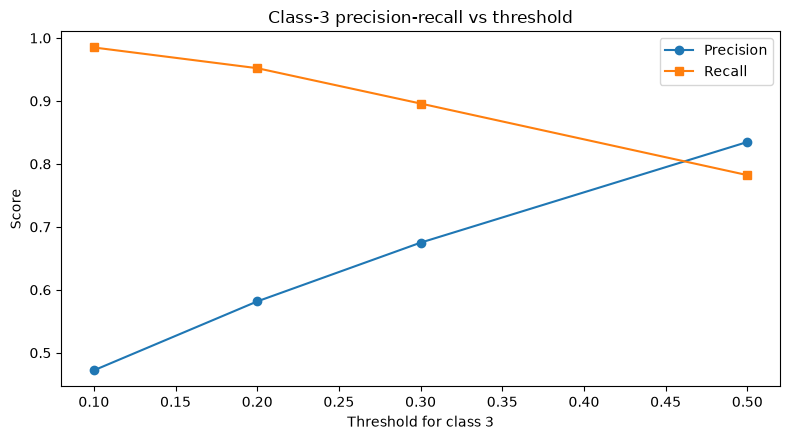

In [5]:
# Precision-recall tradeoff for class 3 across thresholds, using the balanced model's probabilities from the previous cell
ths=[0.1,0.2,0.3,0.5]; precs=[]; recs=[]
for th in ths:
    pp=(p3>=th).astype(int); precs.append(precision_score(ybin,pp,zero_division=0)); recs.append(recall_score(ybin,pp,zero_division=0))
plt.plot(ths, precs, marker="o", label="Precision"); plt.plot(ths, recs, marker="s", label="Recall"); plt.xlabel("Threshold for class 3"); plt.ylabel("Score"); plt.title("Class-3 precision-recall vs threshold"); plt.legend(); plt.tight_layout(); plt.show()

## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.